# NUMCC – Machine Learning Practical
## Session 03: Exploratory Data Analysis (EDA) & Data Visualization

**Dataset:** Titanic  
**Environment:** Google Colab  
**Level:** Beginner

### Learning objectives
By the end of this notebook, you should be able to:
- Explain what Exploratory Data Analysis (EDA) is and why it matters.
- Ask useful questions about a dataset before building a machine learning model.
- Explore numerical and categorical columns.
- Choose suitable charts for different types of data.
- Identify patterns, relationships, missing values, and possible outliers.
- Write simple conclusions supported by evidence from charts and summary statistics.

> **Important:** This notebook focuses on understanding and communicating what is in the data. We are not training a machine learning model in this session.

## 1. What is EDA?

**Exploratory Data Analysis (EDA)** is the process of examining a dataset to understand its structure, quality, distributions, and relationships before performing further analysis or building a model.

Think of EDA as asking questions about your data instead of immediately trying to predict something.

For the Titanic dataset, examples of useful questions are:
- How many passengers survived?
- Were passengers in some passenger classes more likely to survive?
- Did survival differ between male and female passengers?
- How were passenger ages distributed?
- Was ticket fare related to passenger class?

### The three common levels of EDA

1. **Univariate analysis:** studies one variable at a time. Example: the distribution of passenger ages.
2. **Bivariate analysis:** studies the relationship between two variables. Example: survival by passenger class.
3. **Multivariate analysis:** studies relationships among three or more variables. Example: survival by sex and passenger class.

EDA commonly combines:
- **Numerical methods:** counts, averages, medians, percentages, and correlations.
- **Visual methods:** histograms, bar charts, box plots, scatter plots, and heatmaps.

## 2. Import the required libraries

We will use:
- **Pandas:** to load and manipulate tabular data.
- **NumPy:** for numerical operations.
- **Matplotlib:** for creating visualizations.
- **Seaborn:** for statistical visualizations built on top of Matplotlib.

If you are using Google Colab, these libraries are usually available already. Run the installation cell only if an import fails.

In [2]:
# Uncomment this line only if one of the libraries is not installed.
# !pip install pandas numpy matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts look consistent and easier to read
sns.set_theme(style="whitegrid")

# Display more columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Load the Titanic dataset

We will use the Titanic dataset that we used in Session 02.

The code below first tries to load the familiar Titanic dataset through Seaborn. If that is unavailable, it downloads the commonly used Titanic training CSV from a public GitHub copy.

The dataset contains passenger information such as age, sex, passenger class, fare, and whether the passenger survived.

**Note:** Different Titanic versions may contain slightly different columns or numbers of rows. Always inspect the dataset you actually loaded.

In [3]:
try:
    df = sns.load_dataset("titanic")
    print("Loaded Titanic dataset using Seaborn.")
except Exception:
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df = pd.read_csv(url)
    print("Loaded Titanic CSV from the fallback source.")

df.head()

Loaded Titanic dataset using Seaborn.


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 3.1 Understand the dataset's dimensions

- `shape` returns the number of rows and columns.
- `columns` displays the column names.
- `head()` shows the first five rows.
- `tail()` shows the last five rows.

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())
display(df.tail())

### 3.2 Inspect data types and non-null values

`info()` gives us:
- The number of rows.
- Column names.
- Non-null counts.
- Data types.
- Approximate memory usage.

This is useful because numerical and categorical columns are usually explored using different methods.

In [ ]:
df.info()

## 4. Start asking questions: basic summaries

Before creating charts, calculate a few summary statistics.

- `describe()` summarizes numerical columns by default.
- `include="all"` also includes categorical columns.
- `value_counts()` counts how often each category appears.

In [ ]:
# Summary of numerical columns
display(df.describe())

# Summary of both numerical and categorical columns
display(df.describe(include="all"))

In [ ]:
# Count the values in selected categorical columns, if they exist
for column in ["survived", "sex", "class", "pclass", "embarked"]:
    if column in df.columns:
        print(f"\nValue counts for {column}:")
        print(df[column].value_counts(dropna=False))

## 5. Check data quality before interpreting charts

EDA is not only about making attractive charts. We must also understand whether the data is complete and reliable.

### 5.1 Missing values

A missing value is information that is not available for a particular row and column.

We will count missing values in each column and calculate their percentage.

In [ ]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)

### 5.2 Duplicate rows

A duplicate row is a repeated record. Duplicates may affect analysis, so we should check whether they exist.

We will only count duplicates here. We will not automatically remove rows because we first need to understand what each row represents.

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 107


### 5.3 Why data quality matters

Suppose many passenger ages are missing. An age histogram will only describe passengers with recorded ages. It may not represent every passenger equally.

Always mention important data limitations when presenting findings. Do not assume that missing information means zero.

## 6. Univariate analysis – exploring one variable

Univariate analysis focuses on a single column.

The visualization depends on the variable type:
- **Numerical variables:** histograms and box plots.
- **Categorical variables:** count plots or bar charts.

Let's begin with passenger age.

In [10]:
# Find the age column, supporting both common Titanic dataset versions
age_col = "age" if "age" in df.columns else "Age"

# Convert to numeric safely, in case the source contains unexpected values
age_values = pd.to_numeric(df[age_col], errors="coerce").dropna()

print("Number of recorded ages:", age_values.count())
print("Mean age:", round(age_values.mean(), 2))
print("Median age:", round(age_values.median(), 2))
print("Minimum age:", age_values.min())
print("Maximum age:", age_values.max())

Number of recorded ages: 714
Mean age: 29.7
Median age: 28.0
Minimum age: 0.42
Maximum age: 80.0


### 6.1 Histogram – understanding a numerical distribution

A **histogram** groups numerical values into intervals called bins. The height of each bar shows how many observations fall within that interval.

Use a histogram to answer questions such as:
- Which age ranges are most common?
- Is the distribution symmetric or skewed?
- Are there unusually high or low values?

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x=age_col, bins=20, kde=True)
plt.title("Distribution of Titanic Passenger Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of passengers")
plt.show()

**How to read this chart:**
- The horizontal axis represents passenger age.
- The vertical axis represents the number of passengers.
- Taller bars indicate age ranges with more passengers.
- The smooth KDE curve gives an approximate view of the distribution's shape.

The chart can help us describe the age distribution, but it does not by itself explain why some age groups are more common.

### 6.2 Box plot – understanding spread and possible outliers

A **box plot** summarizes a numerical variable using:
- The median (middle line).
- The lower and upper quartiles (the box).
- Whiskers showing the range under the plotting rule.
- Individual points that may be potential outliers.

A point outside the whiskers is not automatically an error. It may be a real observation.

In [ ]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=age_values)
plt.title("Box Plot of Passenger Ages")
plt.xlabel("Age (years)")
plt.show()

### 6.3 Count plot – exploring a categorical variable

A **count plot** displays the number of observations in each category.

For example, we can count how many passengers were recorded in each sex category.

In [ ]:
sex_col = "sex" if "sex" in df.columns else "Sex"

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=sex_col)
plt.title("Number of Passengers by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of passengers")
plt.show()

### 6.4 Bar chart of survival counts

In the Seaborn version, `survived` is coded as 0 (did not survive) and 1 (survived). In the CSV version, the same coding is used.

A bar chart makes the count in each outcome easy to compare.

In [ ]:
survived_col = "survived" if "survived" in df.columns else "Survived"

survival_counts = df[survived_col].value_counts().sort_index()
survival_labels = ["Did not survive" if value == 0 else "Survived"
                   for value in survival_counts.index]

plt.figure(figsize=(7, 4))
plt.bar(survival_labels, survival_counts.values)
plt.title("Titanic Survival Counts")
plt.xlabel("Outcome")
plt.ylabel("Number of passengers")
plt.show()

display(survival_counts.rename(index={0: "Did not survive", 1: "Survived"}))

## 7. Bivariate analysis – exploring relationships between two variables

Bivariate analysis helps us investigate whether two variables appear to be related.

Examples:
- Does survival differ by sex?
- Does passenger class relate to survival?
- Is fare associated with age?

A relationship in a chart does not automatically prove that one variable caused the other.

### 7.1 Survival by sex

A grouped count plot lets us compare survival outcomes within each sex category.

First, we create readable survival labels so the chart is easier to understand.

In [ ]:
plot_df = df.copy()
plot_df["Survival status"] = plot_df[survived_col].map({
    0: "Did not survive",
    1: "Survived"
})

plt.figure(figsize=(8, 5))
sns.countplot(data=plot_df, x=sex_col, hue="Survival status")
plt.title("Survival Counts by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of passengers")
plt.legend(title="Survival status")
plt.show()

**Important interpretation tip:** These are counts, not survival percentages. If one group contains more passengers than another, raw counts can be misleading.

Let's calculate the survival rate for each group.

In [16]:
survival_rate_by_sex = df.groupby(sex_col)[survived_col].mean() * 100
display(survival_rate_by_sex.round(2).rename("Survival Rate (%)"))

,Survival Rate (%)
sex,
female,74.20
male,18.89


### 7.2 Survival by passenger class

Passenger class is often represented as:
- 1: First class
- 2: Second class
- 3: Third class

The Seaborn dataset may use a text column called `class`, while the CSV version commonly uses `Pclass`. We will create one consistent column for plotting.

In [ ]:
if "pclass" in df.columns:
    class_col = "pclass"
elif "Pclass" in df.columns:
    class_col = "Pclass"
else:
    # Seaborn Titanic data has a categorical 'class' column
    class_col = "class"

plt.figure(figsize=(8, 5))
sns.countplot(data=plot_df, x=class_col, hue="Survival status")
plt.title("Survival Counts by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.legend(title="Survival status")
plt.show()

In [18]:
survival_rate_by_class = df.groupby(class_col, observed=False)[survived_col].mean() * 100
display(survival_rate_by_class.round(2).rename("Survival Rate (%)"))

,Survival Rate (%)
pclass,
1,62.96
2,47.28
3,24.24


### 7.3 Scatter plot – comparing two numerical variables

A **scatter plot** displays each observation as a point using two numerical variables.

We will compare passenger age and ticket fare.

Look for:
- A general upward or downward pattern.
- Clusters of points.
- Unusual points far away from most observations.
- Whether there is no obvious pattern.

In [ ]:
fare_col = "fare" if "fare" in df.columns else "Fare"

scatter_df = df[[age_col, fare_col]].copy()
scatter_df[age_col] = pd.to_numeric(scatter_df[age_col], errors="coerce")
scatter_df[fare_col] = pd.to_numeric(scatter_df[fare_col], errors="coerce")
scatter_df = scatter_df.dropna()

plt.figure(figsize=(9, 5))
sns.scatterplot(data=scatter_df, x=age_col, y=fare_col, alpha=0.6)
plt.title("Passenger Age vs. Ticket Fare")
plt.xlabel("Age (years)")
plt.ylabel("Fare")
plt.show()

### 7.4 Box plot – comparing a numerical variable across categories

A box plot can also compare a numerical variable across groups.

Here we compare ticket fares across passenger classes. This helps us see differences in the typical fare and the spread of fares between classes.

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=class_col, y=fare_col)
plt.title("Ticket Fare Distribution by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Ticket fare")
plt.show()

## 8. Multivariate analysis – exploring several variables together

Multivariate analysis looks at patterns involving three or more variables.

For example, we can compare survival across passenger class while separating the results by sex.

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_df,
    x=class_col,
    y=survived_col,
    hue=sex_col,
    errorbar=None
)
plt.title("Survival Rate by Passenger Class and Sex")
plt.xlabel("Passenger class")
plt.ylabel("Average survival value (survival rate)")
plt.legend(title="Sex")
plt.ylim(0, 1)
plt.show()

**Why does this work?**

The survival column contains 0 and 1:
- 0 means the passenger did not survive.
- 1 means the passenger survived.

The average of a column containing only 0s and 1s is the proportion of 1s. Therefore, the average survival value represents the survival rate.

The chart allows us to compare groups, but it does not establish causation.

### 8.1 Correlation – measuring linear relationships

Correlation measures the direction and strength of a **linear relationship** between numerical variables.

The correlation coefficient ranges from -1 to +1:
- Close to **+1:** strong positive linear relationship.
- Close to **-1:** strong negative linear relationship.
- Close to **0:** weak or no linear relationship.

Correlation does not prove causation. Also, a correlation near zero does not rule out every possible non-linear relationship.

In [ ]:
# Select numerical columns only
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

### 8.2 Heatmap – visualizing correlations

A **heatmap** uses color to represent values in a table. It is useful for viewing many correlations at once.

The annotations show the correlation coefficients.

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Titanic Variables")
plt.show()

### 8.3 Pair plot – viewing several numerical relationships

A **pair plot** creates a grid of charts:
- The diagonal shows the distribution of each numerical variable.
- The other cells show relationships between pairs of variables.

Pair plots are useful for smaller sets of numerical columns. Too many columns can make the result slow and difficult to read.

In [ ]:
pair_columns = [column for column in [age_col, fare_col] if column in df.columns]

if "sibsp" in df.columns:
    pair_columns.append("sibsp")
elif "SibSp" in df.columns:
    pair_columns.append("SibSp")

pair_data = df[pair_columns].apply(pd.to_numeric, errors="coerce").dropna()

sns.pairplot(pair_data, corner=True)
plt.show()

## 9. Choosing the right visualization

Different charts answer different questions. Choosing the wrong chart can make a result confusing or misleading.

| Your goal | Recommended chart | Example |
|---|---|---|
| See the distribution of a numerical variable | Histogram | Passenger ages |
| See spread and potential outliers | Box plot | Passenger fares |
| Count categories | Count plot / bar chart | Passengers by sex |
| Compare a numerical measure across categories | Bar plot / box plot | Survival rate by class |
| Explore two numerical variables | Scatter plot | Age vs. fare |
| View many numerical correlations | Heatmap | Correlation matrix |
| Explore several numerical pairs | Pair plot | Age, fare, family count |

### A quick reminder
- Histograms show distributions.
- Count plots show category counts.
- Bar plots compare a numerical summary across categories.
- Box plots show distributions across groups.
- Scatter plots show relationships between numerical variables.
- Heatmaps show values using color.

## 10. Turning analysis into insights

A chart is not the final result. A useful analyst explains what the chart shows.

Use this simple structure when writing an insight:

1. **Observation:** What do you see?
2. **Evidence:** Which count, percentage, or chart supports it?
3. **Limitation:** What should the reader be careful about?

Example:

> The survival rate differs between passenger groups. The grouped survival-rate chart and the calculated percentages support this observation. However, this comparison alone does not prove why the difference exists.

Avoid statements that go beyond the evidence. For example, do not say that a variable *caused* survival just because the chart shows an association.

## 11. Mini analysis: answer questions using the dataset

Run the cells and use the results to write short answers.

### Question 1
What percentage of passengers survived?

In [25]:
overall_survival_rate = df[survived_col].mean() * 100
print(f"Overall survival rate: {overall_survival_rate:.2f}%")

Overall survival rate: 38.38%


### Question 2
Which sex category has the higher survival rate?

In [26]:
display(
    (df.groupby(sex_col)[survived_col].mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .rename("Survival Rate (%)")
)

,Survival Rate (%)
sex,
female,74.20
male,18.89


### Question 3
Which passenger class has the highest survival rate?

In [27]:
display(
    (df.groupby(class_col, observed=False)[survived_col].mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .rename("Survival Rate (%)")
)

,Survival Rate (%)
pclass,
1,62.96
2,47.28
3,24.24


### Question 4
What is the median passenger age?

In [28]:
print("Median passenger age:", round(pd.to_numeric(df[age_col], errors="coerce").median(), 2))

Median passenger age: 28.0


## 12. Student task – perform your own Titanic EDA

Now it is your turn to explore the dataset independently. Use the techniques demonstrated in this notebook.

### Task requirements

Create a new section in your notebook and complete all of the following:

**Part A – Dataset overview**
1. Display the first 10 rows.
2. Display the dataset shape and column names.
3. Show data types and missing-value counts.
4. Identify at least two columns with missing values, if any.

**Part B – Univariate analysis**
5. Create a histogram for passenger age.
6. Create a count plot for passenger class.
7. Create a box plot for ticket fare.
8. Write one observation for each chart.

**Part C – Bivariate analysis**
9. Create a chart comparing survival counts by passenger class.
10. Calculate survival rates by sex.
11. Create a scatter plot comparing age and fare.
12. Write two evidence-based observations.

**Part D – Multivariate analysis**
13. Create a chart showing survival rate by passenger class and sex.
14. Create a correlation heatmap for numerical columns.
15. Explain one interesting pattern you notice.

**Part E – Final conclusion**
16. Write a short conclusion (5–8 sentences) summarizing what you learned from your analysis.
17. Mention at least one limitation of the dataset or your analysis.

### Submission checklist

- [ ] All code cells run without errors.
- [ ] All required charts are included and have clear titles and axis labels.
- [ ] Each chart has a short written interpretation.
- [ ] Percentages are not confused with raw counts.
- [ ] The final conclusion is based on evidence.
- [ ] The notebook is saved and uploaded to GitHub.

### Suggested final notebook name

`NUMCC_Session_03_EDA_Visualization.ipynb`

In [68]:
display(df.head(10))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,Survival status
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Did not survive
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Survived
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Survived
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Survived
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Did not survive
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True,Did not survive
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,Did not survive
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False,Did not survive
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False,Survived
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False,Survived


In [69]:
print("dataset shape: ", df.shape)
print("columns name" , df.columns.tolist())

dataset shape:  (891, 16)
columns name ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone', 'Survival status']


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   survived         891 non-null    int64   
 1   pclass           891 non-null    int64   
 2   sex              891 non-null    object  
 3   age              714 non-null    float64 
 4   sibsp            891 non-null    int64   
 5   parch            891 non-null    int64   
 6   fare             891 non-null    float64 
 7   embarked         889 non-null    object  
 8   class            891 non-null    category
 9   who              891 non-null    object  
 10  adult_male       891 non-null    bool    
 11  deck             203 non-null    category
 12  embark_town      889 non-null    object  
 13  alive            891 non-null    object  
 14  alone            891 non-null    bool    
 15  Survival status  891 non-null    object  
dtypes: bool(2), category(2), float64(2), int64(4

In [71]:
print(df.isna().sum())

survived             0
pclass               0
sex                  0
age                177
sibsp                0
parch                0
fare                 0
embarked             2
class                0
who                  0
adult_male           0
deck               688
embark_town          2
alive                0
alone                0
Survival status      0
dtype: int64


age, deck, embarked and embark town have missing values

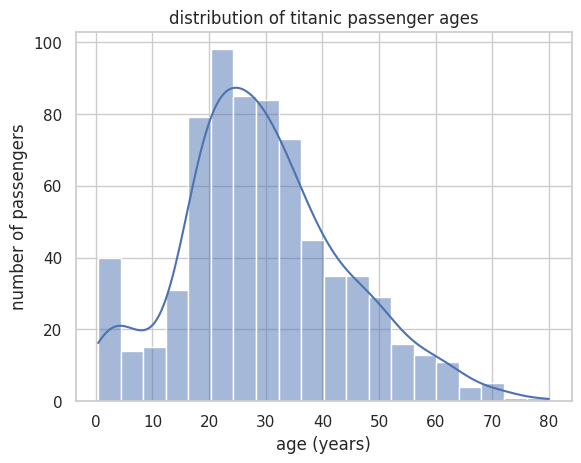

In [72]:
plt.figure()
sns.histplot(data=df, x=age_col, bins=20, kde=True)
plt.title("distribution of titanic passenger ages")
plt.xlabel("age (years)")
plt.ylabel("number of passengers")
plt.show()

most passengers were in their early twenties to mid thirties

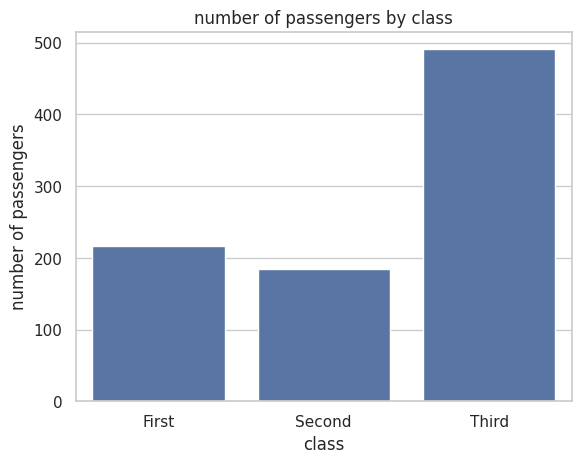

In [73]:
class_col = "class" if "class" in df.columns else "Class"

plt.figure()
sns.countplot(data=df, x=class_col)
plt.title("number of passengers by class")
plt.xlabel("class")
plt.ylabel("number of passengers")
plt.show()

the third class had the most number of passengers

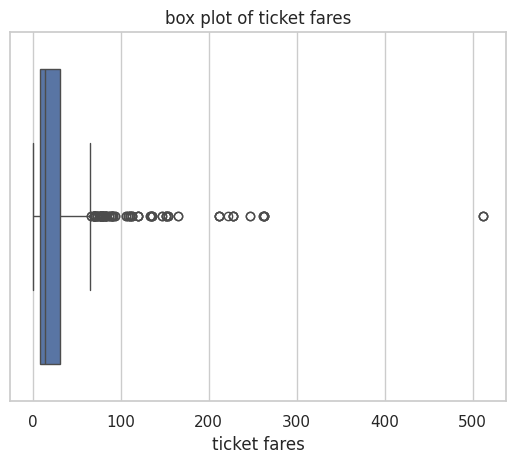

In [74]:
plt.figure()
sns.boxplot(data=df, x="fare")
plt.title("box plot of ticket fares")
plt.xlabel("ticket fares")
plt.show()

an outlier above 500

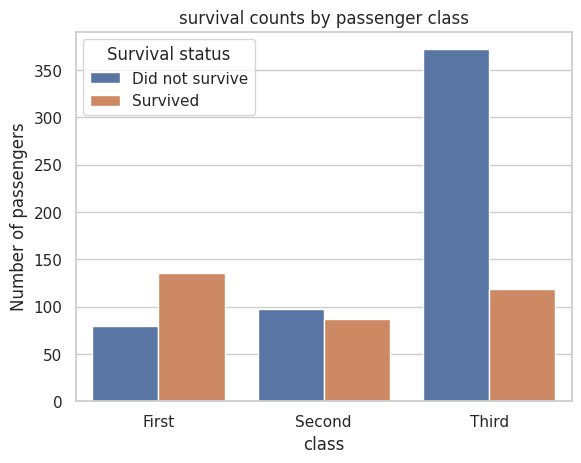

In [75]:
df["Survival status"] = df[survived_col].map({
    0: "Did not survive",
    1: "Survived"
})

plt.figure()
sns.countplot(data=df, x=class_col, hue="Survival status")
plt.title("survival counts by passenger class")
plt.xlabel("class")
plt.ylabel("Number of passengers")
plt.legend(title="Survival status")
plt.show()


In [76]:
survival_rate_by_sex = df.groupby(sex_col)[survived_col].mean() * 100
display(survival_rate_by_sex.round(2).rename("Survival Rate (%)"))

,Survival Rate (%)
sex,
female,74.20
male,18.89


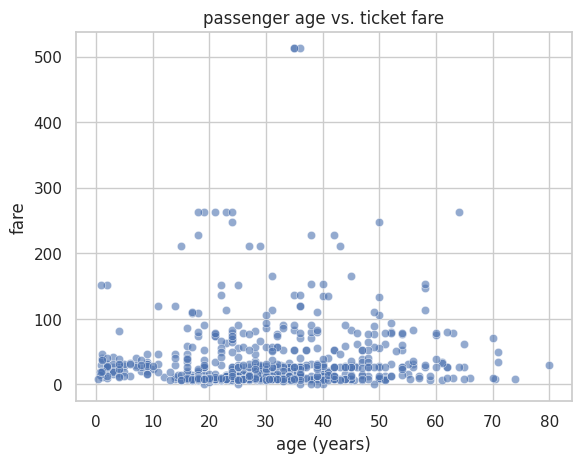

In [77]:
fare_col = "fare" if "fare" in df.columns else "Fare"

scatter_df = df[[age_col, fare_col]].copy()
scatter_df[age_col] = pd.to_numeric(scatter_df[age_col], errors="coerce")
scatter_df[fare_col] = pd.to_numeric(scatter_df[fare_col], errors="coerce")
scatter_df = scatter_df.dropna()

plt.figure()
sns.scatterplot(data=scatter_df, x=age_col, y=fare_col, alpha=0.6)
plt.title("passenger age vs. ticket fare")
plt.xlabel("age (years)")
plt.ylabel("fare")
plt.show()

females had a higher survival rate. vpeople in the third passsenger class had lower survival chance than the other 2 classes

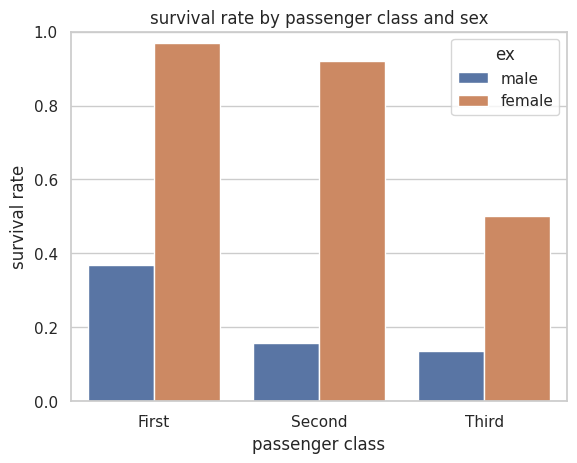

In [78]:
plt.figure()
sns.barplot(
    data=plot_df,
    x=class_col,
    y=survived_col,
    hue=sex_col,
    errorbar=None
)
plt.title("survival rate by passenger class and sex")
plt.xlabel("passenger class")
plt.ylabel("survival rate")
plt.legend(title="ex")
plt.ylim(0, 1)
plt.show()

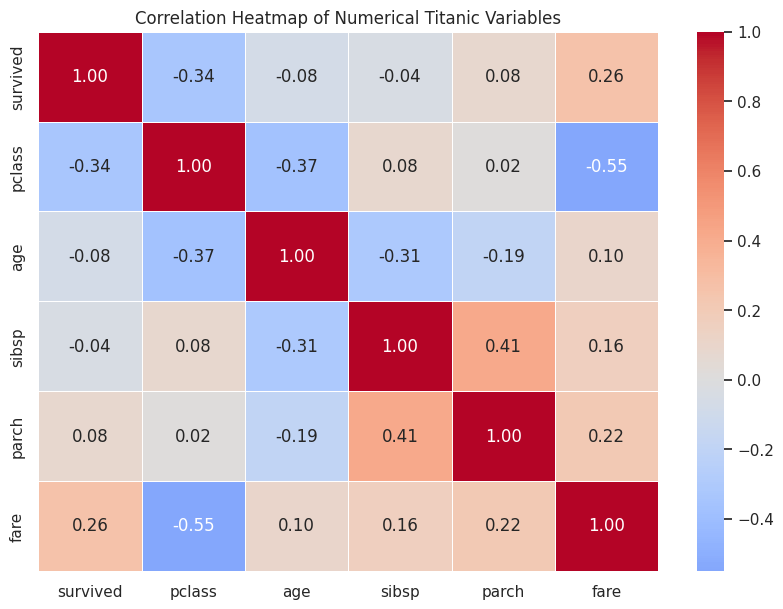

In [79]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Titanic Variables")
plt.show()

fares and pclass have a negative correlation of -0.55, parch of sibsp have a positive correlation of 0.41

## summary
i've learned how to explore datasets using diagrams such as histogram, count plot, box plot, scatter plot and heat maps to identify any potential outliers and understand correlations between numerical values. it helped me with getting a better understanding on how different properies were related to the survival rates. for example females having a higher survival rate than males. most people belonging to passenger class 3, and passenger class 3 having a lower survival rate than both class 1 and 2.

## 13. Session summary

In this practical session, we learned that:
- EDA helps us understand data before modeling.
- Univariate analysis explores one variable.
- Bivariate analysis explores relationships between two variables.
- Multivariate analysis explores patterns involving several variables.
- Histograms, count plots, box plots, scatter plots, bar plots, heatmaps, and pair plots each serve different purposes.
- Summary statistics and visualizations complement each other.
- Charts should be interpreted carefully: association does not prove causation.

**Next step:** Use these EDA skills to understand a dataset before deciding how to prepare it for a machine learning workflow.